In [35]:
import numpy as np
import matplotlib.pyplot as plt

In [36]:
arr = np.loadtxt('scidar_profs_eso_sup.csv',delimiter=",",dtype=str)

In [37]:
heights = np.array(arr[1,8::4],dtype=float)
cn2dhs_str = arr[1:,9::4]
del arr
cn2dhs = np.zeros(cn2dhs_str.shape,dtype=float)
dh = heights[1]-heights[0]
for i in np.arange(cn2dhs_str.shape[0]):
    for j in np.arange(cn2dhs_str.shape[1]):
        if cn2dhs_str[i,j] == '':
            cn2dhs[i,j] = np.nan
        else:
            cn2dhs[i,j] = cn2dhs_str[i,j]
del cn2dhs_str

In [38]:
Q = 3
PROFILE = np.zeros((Q,heights.shape[0]),dtype=float)

PROFILE[0] = np.nanquantile(cn2dhs,0.25,axis=0)
PROFILE[1] = np.nanmedian(cn2dhs,axis=0)
PROFILE[2] = np.nanquantile(cn2dhs,0.75,axis=0)

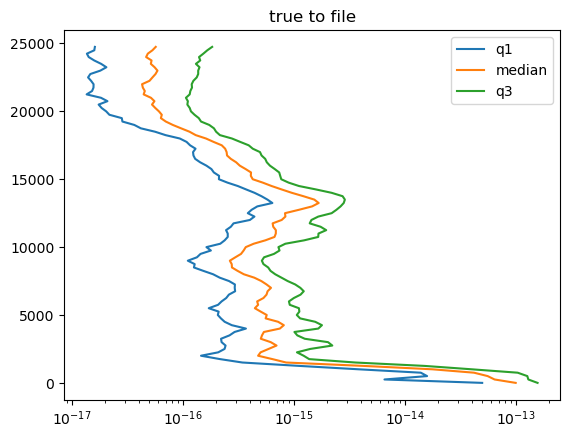

In [39]:
plt.plot(PROFILE[0],heights,label='q1')
plt.plot(PROFILE[1],heights,label='median')
plt.plot(PROFILE[2],heights,label='q3')
plt.xscale('log')
plt.legend()
plt.title('true to file')
plt.show()

#export = np.zeros((4,heights.shape[0]),dtype=float)
#export[0] = heights
#export[1] = PROFILE[0]
#export[2] = PROFILE[1]
#export[3] = PROFILE[2]
#np.savetxt('paranalProfile.csv', export, delimiter=',')

export = np.zeros((4,heights.shape[0]),dtype=float)
export[0] = heights
export[1] = PROFILE[1]
np.savetxt('paranalProfile.csv', export, delimiter=',')


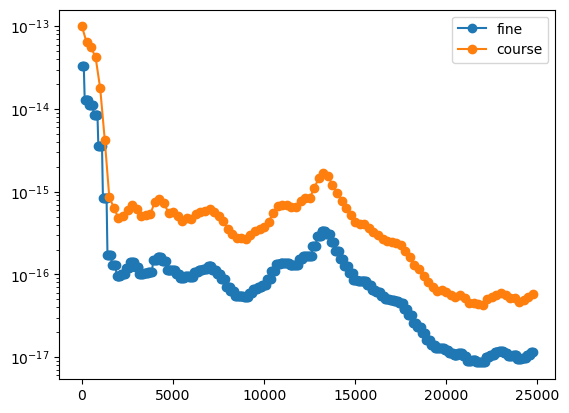

3.23421016e-13 3.2344387999999994e-13


In [40]:
fine_height = np.arange(start=heights.min(),stop=heights.max()+50,step=50)
fine_profile = np.zeros(fine_height.shape[0],dtype=float)
fine_profile[0:3] = PROFILE[1,0]/3.
for i in np.arange(PROFILE.shape[1]):
    if i == 0:
        continue
    fine_profile[5*i-2:5*i+3] = PROFILE[1][i]/5.
plt.plot(fine_height,fine_profile,marker='o',label='fine')
plt.plot(heights,PROFILE[1],marker='o',label='course')
plt.yscale('log')
plt.legend()
plt.show()
print(fine_profile.sum(),PROFILE[1].sum())

In [41]:
def cn2dz2r0(cn2dz,wvl=500e-9):
    r0 = (0.423*(2.*np.pi/wvl)**2*cn2dz)**(-3./5.)
    return r0

def r02cn2dz(r0,wvl=500e-9):
    cn2dz = r0**(-5./3.)/(0.423*(2.*np.pi/wvl)**2)
    return cn2dz


In [42]:
for q in range(Q):
    PROFILE[q] /= PROFILE[q].sum()
cn2dz_10cm_500nm = r02cn2dz(0.1,500e-9)
PROFILE *= cn2dz_10cm_500nm

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


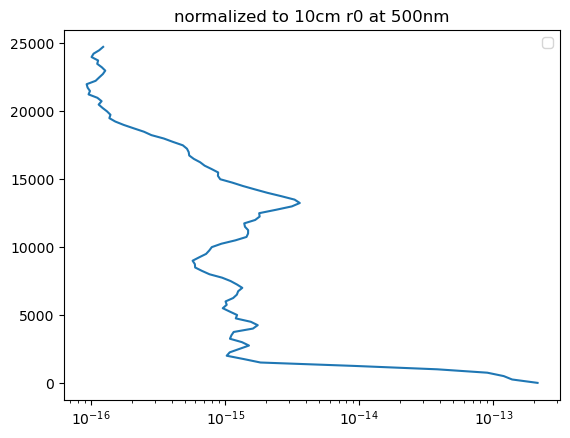

In [43]:
#plt.plot(PROFILE[0],heights,label='q1')
plt.plot(PROFILE[1],heights)#,label='median')
#plt.plot(PROFILE[2],heights,label='q3')
plt.xscale('log')
plt.legend()
plt.title('normalized to 10cm r0 at 500nm')
plt.show()

In [44]:
arr = np.loadtxt('current-mcao-dm-config.csv',delimiter=",",dtype=str)
for i in range(arr.shape[0]):
    for j in range(arr.shape[1]):
        if arr[i,j] == '':
            arr[i,j] = 'nan'
# dkist arr[1::9]
# est arr[2::9]
# gems arr[3::9]
# mavis arr[4::9]
# nfiraos arr[5::9]
# morfeo arr[6::9]
# mad arr[7::9]

In [45]:
n_instru = 7
ndms = np.array(arr[1:8,1],dtype=int)
dm_heights = np.array(arr[1 + 9 : 8 + 9,1:],dtype=float)*1000
dm_heights_radius = np.array(arr[1 + 9*2 : 8 + 9*2,1:],dtype=float)*1000/2 # given values are double lenslet shift, too lazy to change input.

In [46]:
LOS = int(3)
cn2dh_instru = np.zeros((n_instru,ndms.max(),LOS), dtype=float)
zeta = np.array([0,30,60],dtype=float)

for instru in range(n_instru):
    for dms in range(ndms[instru]):
        for los in range(LOS):
            #if dm_heights[instru,dms] == 0:
            #    km_heights = 1000*np.cos(np.radians(zeta[los]))
            #    loc = np.where(heights>km_heights)[0]
            #    bin_cn2dh = PROFILE[1,:loc]
            #else:
            bin_cn2dh = 0
            max_heights = dm_heights[instru,dms] + dm_heights_radius[instru,dms]
            min_heights = dm_heights[instru,dms] - dm_heights_radius[instru,dms]
            for h in range(fine_height.shape[0]):
                los_h = fine_height[h]*np.cos(np.radians(zeta[los])) # convert h to z
                #if los == 2 and instru == 1 and dms == 1 and h > 490:
                #    print(min_heights,los_h,max_heights)
                if (los_h > min_heights) and (los_h < max_heights):
                    #if h != 0:
                    bin_cn2dh += fine_profile[h] # sum cn2dh
                    #else:
                    #    bin_cn2dh += PROFILE[q,h]/np.cos(np.radians(zeta[los]))
            cn2dh_instru[instru,dms,los] = bin_cn2dh/np.cos(np.radians(zeta[los])) # convert dh to dz 

In [47]:

#for instru in range(n_instru):
#    if instru != 6:
#        continue
#    for los in range(LOS):
#        for dms in range(ndms[instru]):
#            #if dm_heights[instru,dms] > 1000:
#            #    continue
#            print(instru,dms,los,'{:.2e}'.format((cn2dh_instru[instru,dms,los])))
#            #print(instru,dms,los,'{:.2f}'.format(cn2dz2r0(cn2dh_instru[instru,dms,los])))


In [48]:
#import pickle
#with open('10cm-dm-cn2dz.pkl','wb') as file:
#    pickle.dump(cn2dh_instru,file)

In [49]:
#cn2dh_instru.shape
data = cn2dh_instru.reshape(7,15)
np.savetxt('10cm-dm-cn2dz.csv', data, delimiter=',', fmt='%s')